# Porosity Classification Study

### Classify porosity into three levels
# - Class 0: Low (<0.5%)
# - Class 1: Medium (0.5–1.0%)
# - Class 2: High (>1.0%)

### Models: Logistic Regression, SVM, Random Forest, Gradient Boosting, MLP

## 1.Import Libraries

In [1]:
# load libraries
import pandas as pd
import numpy as np
import pathlib as Path
import matplotlib.pyplot as plt
import seaborn as sns
import os
from time import time 
import warnings
warnings.filterwarnings('ignore')


# Sklearn
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV

# preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Metrics
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay, precision_recall_curve, precision_recall_fscore_support

# Imbalanced data handling
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import joblib

# Plotting
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')



## 2. Load Processing Data and create classification Labels

In [2]:
df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")  
# features and continuous target
features = ["Power", "Speed", "Feed"]
X = df[features].copy()
y_continuous = df["porosity_%"].copy()

print(f"features shape: {X.shape}")
print(f"continuous target shape: {y_continuous.shape}")

# porosity distribution

print("Porosity distribution:")
print(y_continuous.describe())  
print(f"\nMin: {y_continuous.min():.2f}%, Max: {y_continuous.max():.2f}%")


features shape: (89, 3)
continuous target shape: (89,)
Porosity distribution:
count    89.000000
mean      0.299607
std       0.466428
min       0.000000
25%       0.000000
50%       0.190000
75%       0.375000
max       3.285000
Name: porosity_%, dtype: float64

Min: 0.00%, Max: 3.29%


### 3. Create Three Class labels


Class distribution:
 Class 0 (Low (<0.5%)): 77 samples (86.52%)
 Class 1 (Medium (0.5%-1.5%)): 9 samples (10.11%)
 Class 2 (High (>1.5%)): 3 samples (3.37%)


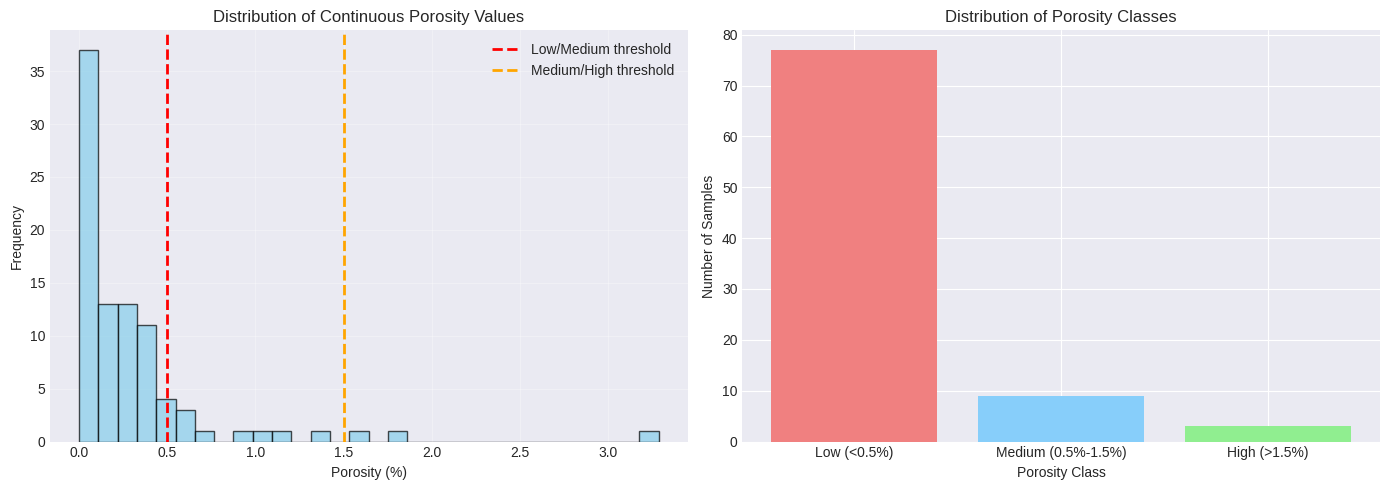

In [3]:


# Define porosity classes

def classify_porosity(porosity):
    """
    Classify porosity into three categories:
    0: Low (<0.5%)
    1: Medium (0.5% - 1%)
    2: High (>1.5%)
    """
    if porosity < 0.5:
        return 0  # Low
    elif 0.5 <= porosity <= 1.5:
        return 1  # Medium
    else:
        return 2  # High    
    
# Apply classification to the continuous target
y = y_continuous.apply(classify_porosity)

# class distribution
class_counts = y.value_counts().sort_index()
class_names = ['Low (<0.5%)', 'Medium (0.5%-1.5%)', 'High (>1.5%)']
print("\nClass distribution:")      

for cls, count in class_counts.items():
    print(f" Class {cls} ({class_names[cls]}): {count} samples ({(count/len(y))*100:.2f}%)")


# Visualize class distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,5))

# Histogram of continuous porosity with thresholds

ax1.hist(y_continuous, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
ax1.axvline(0.5, color='red', linestyle='--', linewidth=2, label='Low/Medium threshold ')
ax1.axvline(1.5, color='orange', linestyle='--', linewidth=2, label='Medium/High threshold')
ax1.set_xlabel('Porosity (%)')
ax1.set_ylabel('Frequency')
ax1.set_title('Distribution of Continuous Porosity Values')
ax1.legend()
ax1.grid(True, alpha=0.3)  

# Bar chart of class counts
class_names = ['Low (<0.5%)', 'Medium (0.5%-1.5%)', 'High (>1.5%)']
bars = ax2.bar(class_names, class_counts.values, color=['lightcoral', 'lightskyblue', 'lightgreen'])
ax2.set_xlabel('Porosity Class')
ax2.set_ylabel('Number of Samples')
ax2.set_title('Distribution of Porosity Classes')

plt.tight_layout()
plt.show()

## 4. Train-Test Stratified

In [4]:
# Train test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)   # ✓ Preserve class distribution

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples\n")

print("Training set class distribution:")
print(y_train.value_counts().sort_index())
print("\nTest set class distribution:")
print(y_test.value_counts().sort_index())   


Training set size: 71 samples
Test set size: 18 samples

Training set class distribution:
porosity_%
0    62
1     7
2     2
Name: count, dtype: int64

Test set class distribution:
porosity_%
0    15
1     2
2     1
Name: count, dtype: int64


## 5. Classification Models with Imbalance Handling


In [10]:
# Define classifiers with Imbalance Handling

# Stratified 5 Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) 


models = {}

#----------Logistic Regression (baseline)----------
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),  # Feature scaling
    ('lr', LogisticRegression(random_state=42, class_weight='balanced', multi_class='multinomial', solver='lbfgs'))
])

lr_params_grid = {
    'lr__C': [0.01, 0.1, 1, 10, 100],  # Regularization strength
    'lr__penalty': ['l2'],  # Regularization type
}

models['Logistic Regression'] = {
    'pipeline': lr_pipe,
    'params': lr_params_grid,
    'search_type': 'grid'
}


#----------SVM (RBF Kernel)----------

svm_pipe = Pipeline([
    ('scaler', StandardScaler()),  # Feature scaling
    ('svm', SVC(kernel='rbf', random_state=42, class_weight='balanced', probability=True)) # to enable probability estimates for ROC-AUC and precision-recall curves
])  

svm_params_grid = {
    'svm__C': [0.1, 1, 10, 100],  # Regularization strength
    'svm__gamma': ['scale', 'auto', 0.01, 0.1, 1],  # Kernel coefficient    
}

models["SVM"] = {
    'pipeline': svm_pipe,
    'params': svm_params_grid,
    'search_type': 'grid'
}

#----------Random Forest----------

rf_pipe = Pipeline([
    ('rf', RandomForestClassifier(random_state=42, class_weight='balanced')) # "balanced" to handle class imbalance
])  # StandardScaler is not needed for tree-based models

rf_params_grid = {
    'rf__n_estimators': [100, 200, 300],  # Number of trees
    'rf__max_depth': [None, 10, 20],  # Maximum depth of the tree
    'rf__min_samples_split': [2, 5],  # Minimum number of samples required to split an internal node
    'rf__min_samples_leaf': [1, 2, 4],  # Minimum number of samples required to be at a leaf node
}

models["Random Forest"] = {
    'pipeline': rf_pipe,
    'params': rf_params_grid,
    'search_type': 'random'  # Use RandomizedSearchCV instead of GridSearchCV for faster hyperparameter tuning
}

#----------Gradient Boosting (XGBoost)----------
gb_pipe = Pipeline([
    ('gb', GradientBoostingClassifier(random_state=42))  # Gradient Boosting does not have a built-in class_weight parameter, but it can handle imbalance to some extent through its boosting mechanism
])  # StandardScaler is not needed for tree-based models        
gb_params_grid = {
    'gb__n_estimators': [100, 200, 300],  # Number of boosting stages
    'gb__learning_rate': [0.01, 0.1, 0.2],  # Learning rate
    'gb__max_depth': [3, 5, 7],  # Maximum depth of the individual regression estimators
    'gb__min_samples_split': [2, 5],  # Minimum number of samples required to split an internal node
    'gb__min_samples_leaf': [1, 2, 4],  # Minimum number of samples required to be at a leaf node
}   
models["Gradient Boosting"] = {
    'pipeline': gb_pipe,
    'params': gb_params_grid,
    'search_type': 'random'  # Use RandomizedSearchCV instead of GridSearchCV for faster hyperparameter tuning
}

#----------Neural Network (MLP)----------
mlp_pipe = Pipeline([
    ('scaler', StandardScaler()),  # Feature scaling is important for neural networks
    ('mlp', MLPClassifier(random_state=42, max_iter=2000, early_stopping=True, validation_fraction=0.15))  # early_stopping to prevent overfitting
])

mlp_params_grid = {
    'mlp__hidden_layer_sizes': [(50,), (50,), (20,10), (100,), (50, 50)],  # Different architectures
    'mlp__activation': ['relu', 'tanh'],  # Activation functions
    'mlp__alpha': [0.0001, 0.001, 0.01],  # L2 regularization parameter
    'mlp__learning_rate_init': [0.001, 0.01],  # Initial learning rate
}

models["Neural Network"] = {
    'pipeline': mlp_pipe,
    'params': mlp_params_grid,
    'search_type': 'random'  # Use RandomizedSearchCV instead of GridSearchCV for faster hyperparameter tuning
}   


print(f"Configured {len(models)} models: {list(models.keys())}\n")






Configured 5 models: ['Logistic Regression', 'SVM', 'Random Forest', 'Gradient Boosting', 'Neural Network']



## 6. Hyperparameter Tuning and Cross Validation

In [12]:
# Hyperparameter Tuning and Model Training

from sklearn.metrics import f1_score
from sklearn.model_selection import cross_validate

results = {}
best_models = {}

# Scoring metrics for multiclass

scoring = {
    'accuracy': 'accuracy',
    'f1_weighted': 'f1_weighted',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro' 
}   

for mode_name, cfg in models.items():
    print(f"Training {mode_name}...")
    start_time = time()
    
    if cfg['search_type'] == 'grid':
        search = GridSearchCV(cfg['pipeline'], cfg['params'], cv=cv, scoring=scoring, refit='f1_weighted', n_jobs=-1, verbose=1)  # refit on the best model according to f1_weighted
    else:
        search = RandomizedSearchCV(cfg['pipeline'], cfg['params'], cv=cv, scoring=scoring, refit='f1_weighted', n_iter=20, random_state=42, n_jobs=-1, verbose = 1 )  # n_iter controls how many parameter settings are sampled
    
    # Fit search on training data
    search.fit(X_train, y_train)
    
    best_est = search.best_estimator_
    best_models[mode_name] = best_est

    #cross-validation the best estimator to get more reliable performance metrics

    cv_results = cross_validate(best_est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=True) 

    # train/test predictions

    y_train_pred = best_est.predict(X_train)
    y_test_pred = best_est.predict(X_test)

    # Get prediction probabilities for ROC-AUC and precision-recall curves
    y_train_proba = best_est.predict_proba(X_train)
    y_test_proba = best_est.predict_proba(X_test)

    # compute per class metrics on testset

    precision, recall, f1, support = precision_recall_fscore_support(y_test, y_test_pred, average=None, labels=[0, 1, 2])


    # multi-class ROC-AUC (one - vs- rest  )

    try:
        roc_auc_ovr = roc_auc_score(y_test, y_test_proba, multi_class='ovr', average='weighted')  # weighted average to account for class imbalance
    except:  
        roc_auc_ovr = np.nan  # If ROC-AUC cannot be computed, set it to NaN

    # Training time
    training_time = time() - start_time

    # Store results
    results[mode_name] = {
        'best_params': search.best_params_,
        'accuracy_cv_mean': cv_results['test_accuracy'].mean(),
        'accuracy_cv_std': cv_results['test_accuracy'].std(),
        'f1_weighted_cv_mean': cv_results['test_f1_weighted'].mean(),
        'f1_weighted_cv_std': cv_results['test_f1_weighted'].std(),
        'f1_weighted_cv_mean': cv_results['test_f1_weighted'].mean(),
        'f1_weighted_cv_std': cv_results['test_f1_weighted'].std(),

        # Test metrics
        'accuracy_test': (accuracy_score(y_test, y_test_pred)),
        'precision_test_class0': precision[0],
        'recall_test_class0': recall[0],
        'f1_test_class0': f1[0],
        'precision_test_class1': precision[1],
        'recall_test_class1': recall[1],
        'f1_test_class1': f1[1],
        'precision_test_class2': precision[2],
        'recall_test_class2': recall[2],
        'f1_test_class2': f1[2],
        'roc_auc_test': roc_auc_ovr,
        'training_time_sec': training_time
    }

print(f"\nBest parameters: {search.best_params_}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Acuracy_CV: {results[mode_name]['accuracy_cv_mean']:.4f} ± {results[mode_name]['accuracy_cv_std']:.4f}")
print(f"F1-Weighted CV: {results[mode_name]['f1_weighted_cv_mean']:.4f} ± {results[mode_name]['f1_weighted_cv_std']:.4f}")
print(f"Test Accuracy: {results[mode_name]['accuracy_test']:.4f}")
print(f"ROC-AUC_Test (OvR): {results[mode_name]['roc_auc_test']:.4f}")  




Training Logistic Regression...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Training SVM...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Training Random Forest...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Training Gradient Boosting...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Training Neural Network...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best parameters: {'mlp__learning_rate_init': 0.001, 'mlp__hidden_layer_sizes': (100,), 'mlp__alpha': 0.0001, 'mlp__activation': 'tanh'}
Training time: 1.51 seconds
Acuracy_CV: 0.9019 ± 0.0558
F1-Weighted CV: 0.8563 ± 0.0815
Test Accuracy: 0.8333
ROC-AUC_Test (OvR): 0.7737


### Summary Table and Best Model

In [15]:
# results 

results_df = pd.DataFrame(results).T  # Transpose for better readability

summary_col = ['accuracy_cv_mean', 'accuracy_cv_std', 'f1_weighted_cv_mean', 'f1_weighted_cv_std', 'accuracy_test', 'roc_auc_test', 'f1_test_class2']

summary_df = results_df[summary_col].round(4).sort_values(by='f1_weighted_cv_mean', ascending=False)  # Sort by F1-Weighted CV mean for better comparison

print('='*80)
print(f"Model Performace Summary - Porosity Classification")
print('='*80)
print(summary_df)

best_model_name = summary_df.index[0]
print(f"Best model: {best_model_name}")
print(f"Accuracy_CV: {summary_df.loc[best_model_name, 'accuracy_cv_mean']:.4f} ± {summary_df.loc[best_model_name, 'accuracy_cv_std']:.4f}")
print(f"F1-Weighted CV: {summary_df.loc[best_model_name, 'f1_weighted_cv_mean']:.4f} ± {summary_df.loc[best_model_name, 'f1_weighted_cv_std']:.4f}")
print(f"Test Accuracy: {summary_df.loc[best_model_name, 'accuracy_test']:.4f}")
print(f"ROC-AUC_Test (OvR): {summary_df.loc[best_model_name, 'roc_auc_test']:.4f}")
print(f"F1 Score for High Porosity Class: {summary_df.loc[best_model_name, 'f1_test_class2']:.4f}")
#print(f"Training time: {summary_df.loc[best_model_name, 'training_time']:.2f} seconds") 
print('='*80)


               


Model Performace Summary - Porosity Classification
                    accuracy_cv_mean accuracy_cv_std f1_weighted_cv_mean  \
SVM                         0.900952        0.057649            0.898515   
Random Forest               0.901905        0.071815            0.869524   
Neural Network              0.901905        0.055826            0.856293   
Gradient Boosting           0.859048        0.045336            0.846032   
Logistic Regression         0.773333        0.072381            0.802672   

                    f1_weighted_cv_std accuracy_test roc_auc_test  \
SVM                           0.073987      0.888889     0.703704   
Random Forest                 0.084527      0.833333     0.952546   
Neural Network                0.081514      0.833333     0.773693   
Gradient Boosting             0.051048      0.944444          1.0   
Logistic Regression           0.045782      0.833333     0.916667   

                    f1_test_class2  
SVM                            1.0  
Ran

## Detailed Classification Reports (ALL models)

In [16]:
# detailed classification report for the best model

for model_name in models.keys():
    print('='*80)
    print(f"\nClassification Report:  {model_name}:")
    print('='*80)
    
    y_test_pred, best_models[model_name].predict(X_test)

    report = classification_report(y_test, y_test_pred, target_names=class_names, digits= 3)
    print(report)

    



Classification Report:  Logistic Regression:
                    precision    recall  f1-score   support

       Low (<0.5%)      0.833     1.000     0.909        15
Medium (0.5%-1.5%)      0.000     0.000     0.000         2
      High (>1.5%)      0.000     0.000     0.000         1

          accuracy                          0.833        18
         macro avg      0.278     0.333     0.303        18
      weighted avg      0.694     0.833     0.758        18


Classification Report:  SVM:
                    precision    recall  f1-score   support

       Low (<0.5%)      0.833     1.000     0.909        15
Medium (0.5%-1.5%)      0.000     0.000     0.000         2
      High (>1.5%)      0.000     0.000     0.000         1

          accuracy                          0.833        18
         macro avg      0.278     0.333     0.303        18
      weighted avg      0.694     0.833     0.758        18


Classification Report:  Random Forest:
                    precision    recal

## Confusion Matrices - All Models

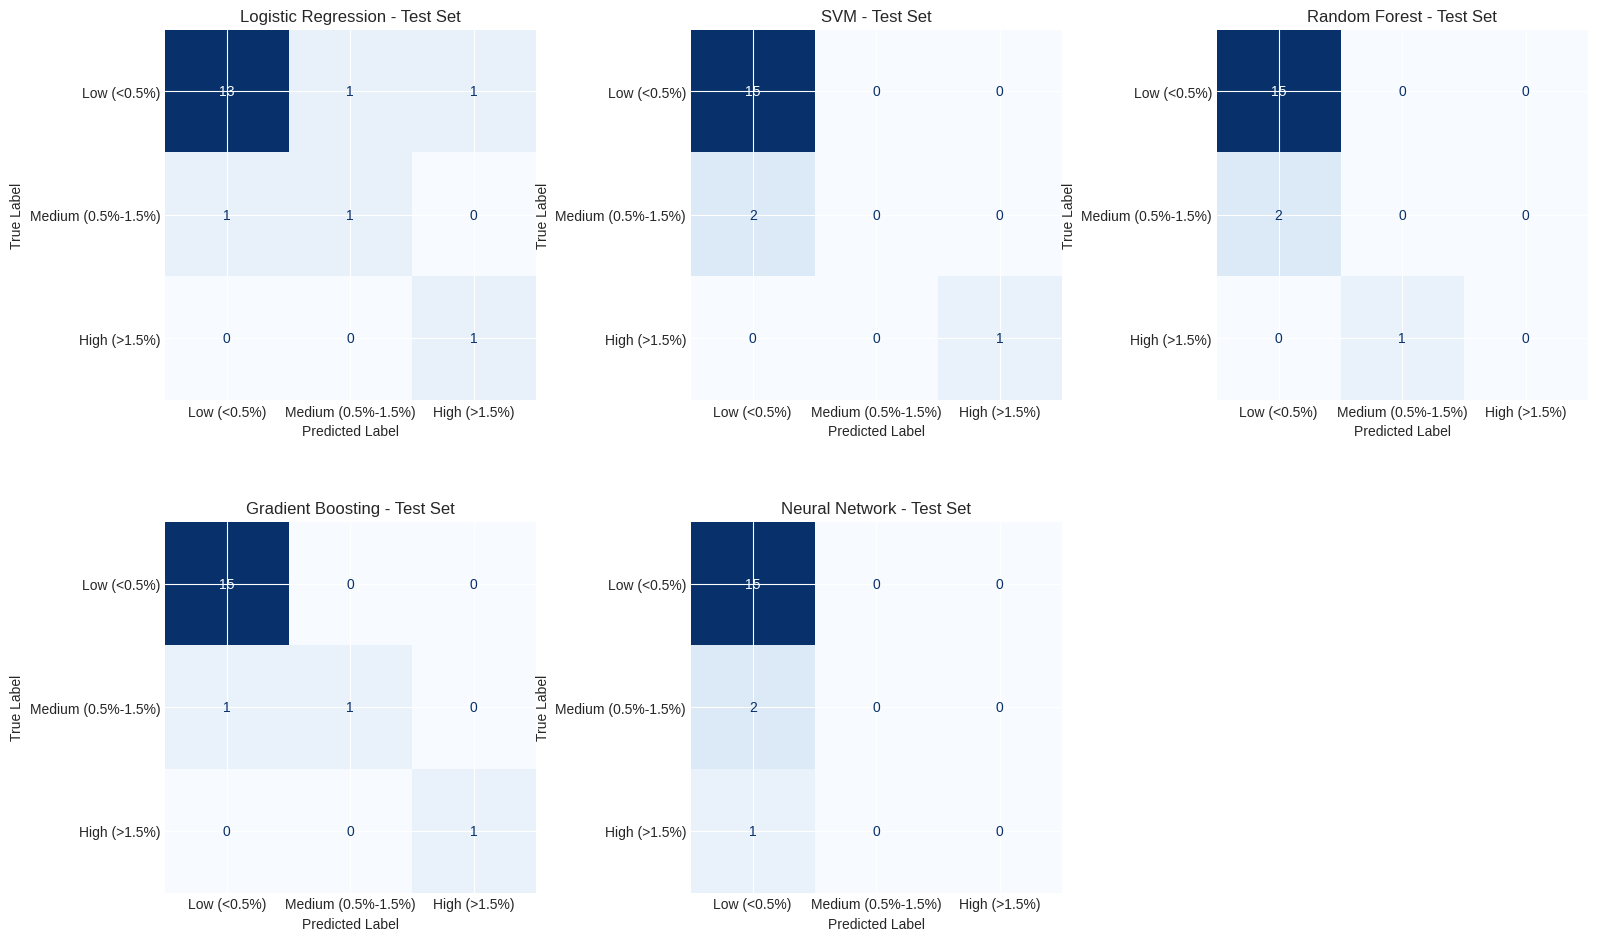

In [17]:
# Confusion Matrices for all models

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for idx, (model_name, best_est) in enumerate(best_models.items()):
    y_test_pred = best_est.predict(X_test)
    cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    ax = axes[idx // 3, idx % 3]
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{model_name} - Test Set")
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

# Hide last subplot if odd number

if len(models) < 6:
    axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

## 10. ROC Curves 
### Receiver Operating Characteristics (One vs Rest for Each Class)

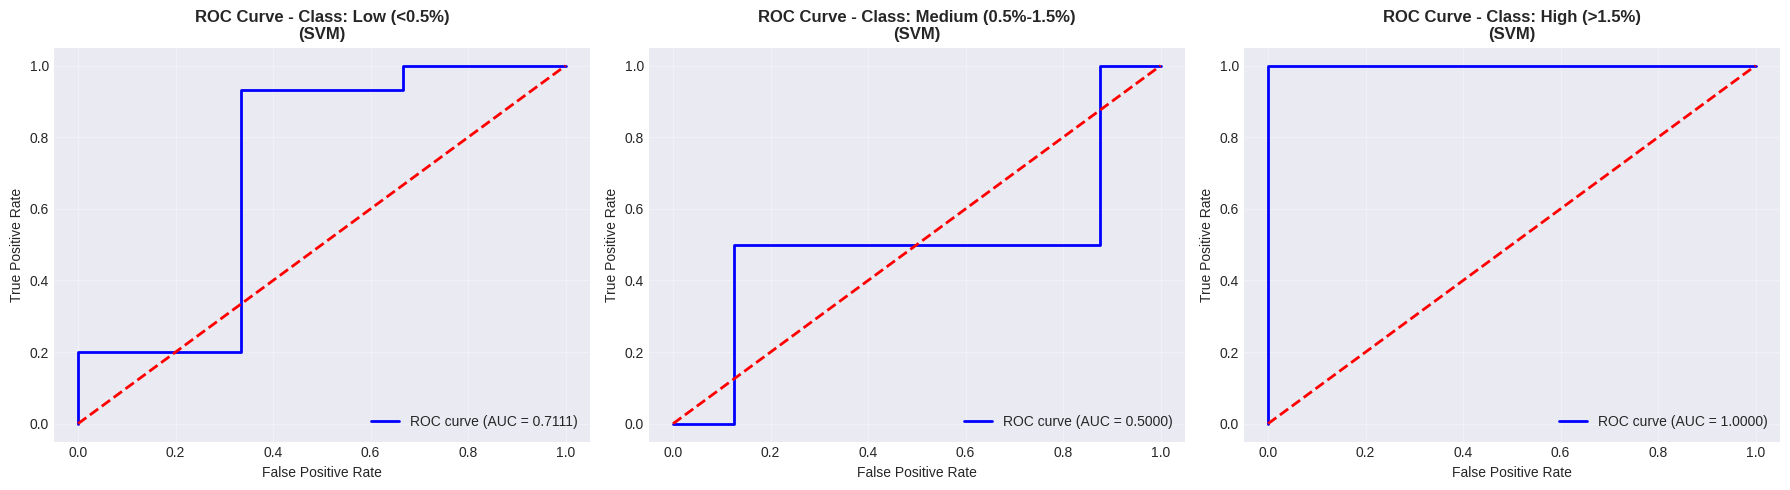

In [18]:
# Plot ROC for best model only Cleaner

best_model = best_models[best_model_name]
y_test_proba = best_model.predict_proba(X_test)

# Compute ROC curve and AUC for each class

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test == i, y_test_proba[:, i])  # One-vs-rest approach
    roc_auc = roc_auc_score(y_test == i, y_test_proba[:, i])
    
    axes[i].plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
    axes[i].plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')  # Diagonal line for random classifier
    axes[i].set_title(f'ROC Curve - Class: {class_name}\n({best_model_name})', fontsize=12, fontweight='bold')
    axes[i].legend(loc="lower right")   
    axes[i].set_xlabel('False Positive Rate')
    axes[i].set_ylabel('True Positive Rate')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()  

### 11. Precision- Reacall Curves (esp- Hogh Porosity)

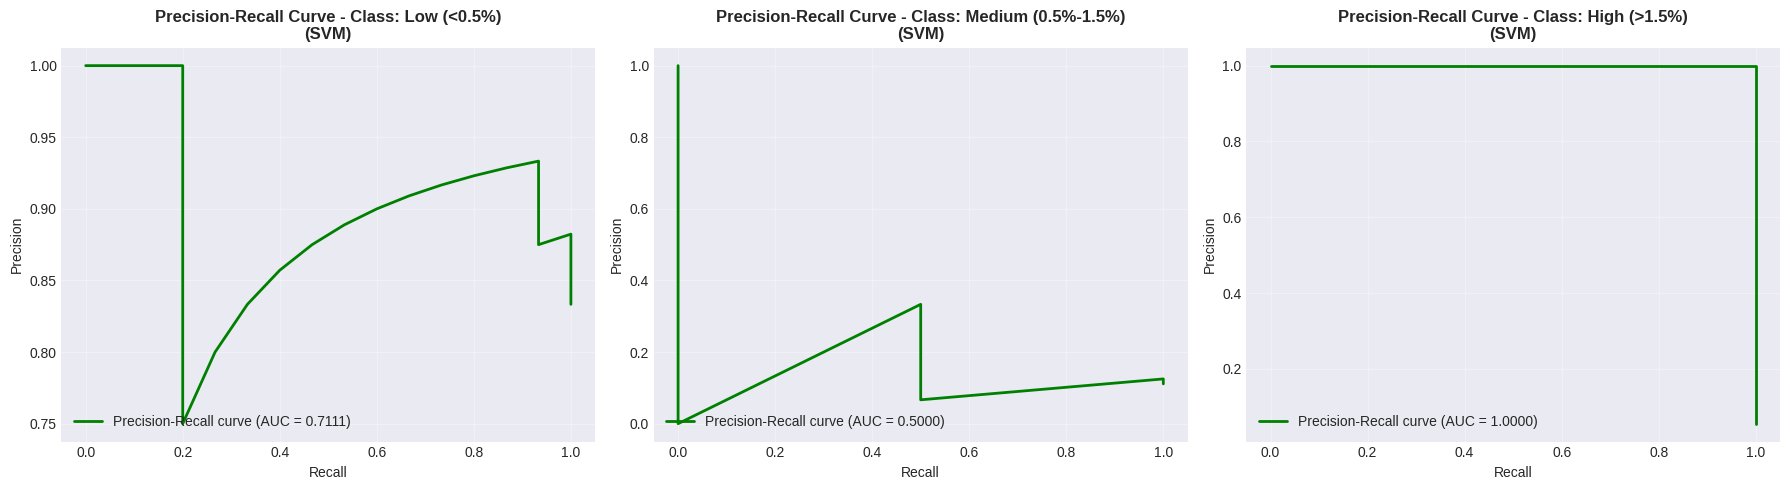

In [19]:
# Precision recall curves

fig, axes = plt.subplots(1, 3, figsize=(18, 5)) 

for i, class_name in enumerate(class_names):
    precision, recall, _ = precision_recall_curve(y_test == i, y_test_proba[:, i])  # One-vs-rest approach
    pr_auc = roc_auc_score(y_test == i, y_test_proba[:, i])  # Using ROC AUC as a proxy for PR AUC in imbalanced settings
    
    axes[i].plot(recall, precision, color='green', lw=2, label=f'Precision-Recall curve (AUC = {pr_auc:.4f})')
    axes[i].set_title(f'Precision-Recall Curve - Class: {class_name}\n({best_model_name})', fontsize=12, fontweight='bold')
    axes[i].legend(loc="lower left")   
    axes[i].set_xlabel('Recall')
    axes[i].set_ylabel('Precision')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 12.Feature Importances (RF/XGBoost) 

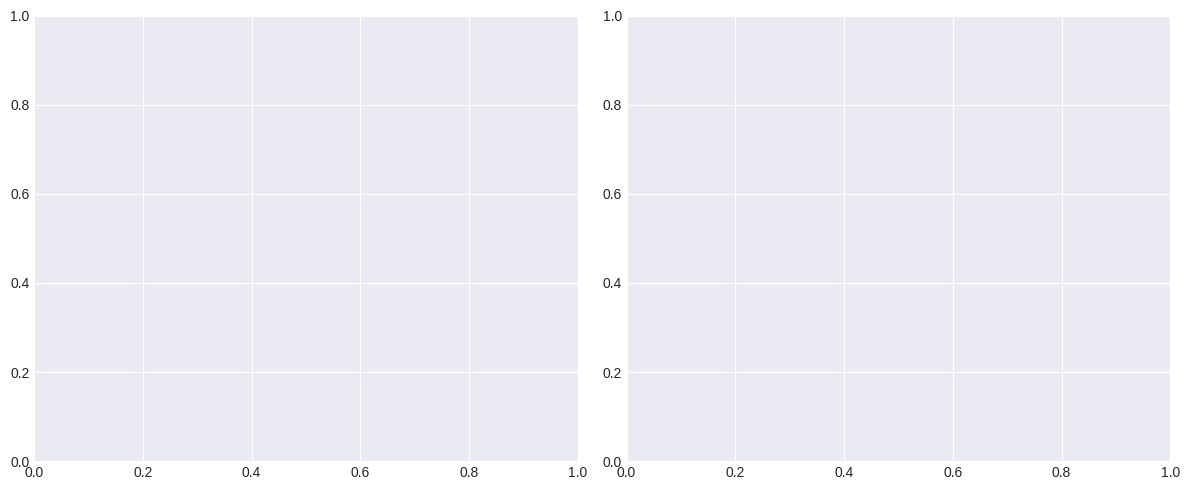

In [23]:
# tree models feature importance for best model if it is tree-based

tree_models = ['RandomForest', 'GradientBoosting']    

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, model_name in enumerate(tree_models):
    if model_name in best_models:
        # extramedel from pipeline
        model = best_models[model_name].named_steps[model_name.lower().replace('gradient', 'g').replace('boosting', 'b')]

        if hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
            feature_names = X.columns
            sorted_indices = np.argsort(importances)[::-1]
            
            axes[idx].bar(range(len(importances)), importances[sorted_indices], color='lightblue', edgecolor='black')
            axes[idx].set_xticks(range(len(importances)))
            axes[idx].set_xticklabels(feature_names[sorted_indices], rotation=45, ha='right')
            axes[idx].set_title(f'Feature Importance - {model_name}', fontsize=12, fontweight='bold')
            axes[idx].set_ylabel('Importance Score')
            axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 13. Save Best Model & Results


In [24]:
# Save results table

results_df.to_csv("~/Documents/PlayTime/LMD_Modelling/results/porosity_classification_results.csv", index=True) 
print("Results saved to porosity_classification_results.csv")   

# save best model for future use

best_model_file = f'BestClassifier_{best_model_name}_porosity.pkl'
joblib.dump(best_models[best_model_name], best_model_file)
print(f"Best model saved to {best_model_file}")



Results saved to porosity_classification_results.csv
Best model saved to BestClassifier_SVM_porosity.pkl


### 14.Final Summary: regrtession Vs Classification

In [26]:
print('='*80)
print("POROSITY MODELLING: REGRESSION vs CLASSIFICATION")
print('='*80)
print("\nREGRESSION (from previous work):")
print("  Best model: SVR / GPR / RF")
print("  R²_test: Strongly negative (-2.1 to -4.8)")
print("  Conclusion: Continuous prediction unreliable")

print("\nCLASSIFICATION (current work):")
print(f"  Best model: {best_model_name}")
print(f"  Accuracy_test: {results[best_model_name]['accuracy_test']:.3f}")
print(f"  F1_High_porosity: {results[best_model_name]['f1_test_class2']:.3f}")
print(f"  ROC-AUC (weighted): {results[best_model_name]['roc_auc_test']:.3f}")

if results[best_model_name]['accuracy_test'] > 0.5:
    print("\n  ✓ Classification provides actionable predictions")
    print("    (better than random, usable for quality control)")
else:
    print("\n  ✗ Even classification struggles")
    print("    (missing key physics: gas flow, powder quality, etc.)")
print('='*80)

POROSITY MODELLING: REGRESSION vs CLASSIFICATION

REGRESSION (from previous work):
  Best model: SVR / GPR / RF
  R²_test: Strongly negative (-2.1 to -4.8)
  Conclusion: Continuous prediction unreliable

CLASSIFICATION (current work):
  Best model: SVM
  Accuracy_test: 0.889
  F1_High_porosity: 1.000
  ROC-AUC (weighted): 0.704

  ✓ Classification provides actionable predictions
    (better than random, usable for quality control)
